# QQQ Volatility Forecasting: Spike Analysis

คำถามวิจัยของโปรเจกต์คือ **การตัดช่วงที่ราคากระชากแรง (spike) ออกจากข้อมูลเทรน ช่วยหรือทำร้ายโมเดล** คำถามนี้จะตอบได้ก็ต่อเมื่อบอกได้ชัดก่อนว่า "spike คือวันไหน" และ "ตัดอะไรออกบ้าง" เล่มนี้อธิบายสองเรื่องนั้นพร้อมหลักฐาน

เล่มนี้ตอบห้าคำถาม

1. ใช้เกณฑ์อะไรตัดสินว่าวันไหนเป็น spike
2. ทำไมเลือกเกณฑ์นั้น แทนที่จะใช้ค่าเฉลี่ยกับส่วนเบี่ยงเบนมาตรฐาน หรือเส้นแบ่งที่เข้มน้อยกว่า
3. ทำไมต้องตัดทั้งช่วงรอบวัน spike ไม่ใช่แค่วันนั้นวันเดียว
4. การตัดเปลี่ยนข้อมูลเทรนอย่างไร
5. ผลต่อโมเดลเป็นอย่างไร

**ขอบเขต:** เล่มนี้อ่านข้อมูล Train และรายงานที่สร้างไว้แล้วเท่านั้น ไม่เทรนโมเดล และไม่เปิดไฟล์ Test เกณฑ์ทางเลือกในหัวข้อ 3 แสดงเฉพาะ "ผลต่อจำนวนข้อมูล" เพื่ออธิบายการตัดสินใจ **ไม่ได้ใช้เลือกเกณฑ์ย้อนหลังจากคะแนนของโมเดล** เกณฑ์หลักถูกกำหนดและตรึงไว้ก่อนเทรนโมเดลตัวแรก

**ลำดับการอ่านที่แนะนำ:** `02_eda_and_features.ipynb` (ข้อมูลและ feature) → `03`–`05` (ผลของโมเดล) → เล่มนี้ (ลงลึกเรื่องเกณฑ์ spike)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

current = Path.cwd().resolve()
project_root = current.parent if current.name == "notebooks" else current
if not (project_root / "config.py").is_file() or not (project_root / "src").is_dir():
    raise FileNotFoundError(f"Could not resolve project root from {current}; expected config.py and src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config import (
    NON_SPIKE_TRAIN_PATH,
    PRIMARY_SPIKE_IQR_MULTIPLIER,
    SPIKE_ANALYSIS_REPORT_PATH,
    SPIKE_DAILY_RETURN_FIGURE_PATH,
    SPIKE_DATASET_COMPARISON_FIGURE_PATH,
    SPIKE_EVENT_AUDIT_PATH,
    SPIKE_FEATURE_FORWARD_REACH,
    SPIKE_TARGET_BACKWARD_REACH,
    WITH_SPIKES_TRAIN_PATH,
)
from src.detect_spikes import apply_spike_detector, fit_primary_spike_detector
from src.spike_contract import build_affected_mask

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
REPORT_ROOT = project_root / "outputs" / "modeling" / "report"
FIGURE_DIR = project_root / "outputs" / "figures" / "modeling" / "spike_rule"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#9aa5b1", "#1f2933"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold"})
get_ipython().run_line_magic("matplotlib", "inline")


def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError("Missing generated artifacts (follow docs/guides/RUNBOOK.md first):\n" + "\n".join(missing))


def show_image(path, width=900):
    require_files([path])
    display(Image(filename=str(path), width=width))


def markdown_table(path):
    """Read one Markdown table written by the report code into a DataFrame."""
    lines = [line for line in Path(path).read_text(encoding="utf-8").splitlines() if line.startswith("|")]
    cells = [[cell.strip() for cell in line.strip("|").split("|")] for line in lines]
    return pd.DataFrame(cells[2:], columns=cells[0])


require_files([WITH_SPIKES_TRAIN_PATH, NON_SPIKE_TRAIN_PATH, SPIKE_ANALYSIS_REPORT_PATH, SPIKE_EVENT_AUDIT_PATH])
train = pd.read_csv(WITH_SPIKES_TRAIN_PATH, parse_dates=["Date"])
report = json.loads(Path(SPIKE_ANALYSIS_REPORT_PATH).read_text(encoding="utf-8"))
returns = train["return_1d"]
absolute = returns.abs()
is_high = train["target_high_volatility"].astype(int)
print("Train:", len(train), "rows |", train["Date"].min().date(), "to", train["Date"].max().date(),
      "| high-volatility days:", int(is_high.sum()))

Train: 1733 rows | 2016-09-29 to 2023-08-18 | high-volatility days: 433


## 1. เกณฑ์ที่ใช้

เกณฑ์หลักของโปรเจกต์คำนวณจาก **ขนาดของผลตอบแทนรายวัน** `|return_1d|` ของ **Train เท่านั้น** มีสี่ขั้น

1. หา **Q1** คือค่าที่ 25% ของวันใน Train ขยับน้อยกว่า
2. หา **Q3** คือค่าที่ 75% ของวันใน Train ขยับน้อยกว่า
3. คำนวณ **IQR = Q3 − Q1** คือความกว้างของ "ช่วงกลาง" ที่วันครึ่งหนึ่งอยู่
4. เส้นแบ่ง = **Q3 + 3 × IQR** วันใดที่ `|return_1d|` **มากกว่า** เส้นนี้นับเป็น spike (ค่าที่เท่ากับเส้นพอดีไม่นับ)

โค้ดของเกณฑ์อยู่ที่ `src/detect_spikes.py` เซลล์ถัดไปเรียกโค้ดนั้นโดยตรง แล้วตรวจว่าได้ค่าเดียวกับที่บันทึกไว้ใน `outputs/reports/spike_analysis.json`

In [2]:
primary = fit_primary_spike_detector(train)
direct = apply_spike_detector(train, primary)

recorded = report["primary_detector"]
assert np.isclose(primary.threshold, recorded["threshold"], rtol=0, atol=1e-15)
assert int(direct.sum()) == report["splits"]["train"]["direct_count"]

display(pd.DataFrame([
    {"step": "Q1 of |return_1d|", "value_pct": 100 * primary.q1},
    {"step": "Q3 of |return_1d|", "value_pct": 100 * primary.q3},
    {"step": "IQR = Q3 - Q1", "value_pct": 100 * primary.iqr},
    {"step": f"threshold = Q3 + {primary.multiplier:g} x IQR", "value_pct": 100 * primary.threshold},
]).round(4))
print(f"Train days above the threshold: {int(direct.sum())} of {len(train)} ({100 * direct.mean():.2f}%)")
print("rule:", primary.comparison_rule, "| fitted on:", primary.source_split, "| quantile method:", primary.quantile_method)

,step,value_pct
0,Q1 of |return_1d|,0.2980
1,Q3 of |return_1d|,1.3871
2,IQR = Q3 - Q1,1.0891
3,threshold = Q3 + 3 x IQR,4.6544


Train days above the threshold: 19 of 1733 (1.10%)
rule: abs(return_1d) > threshold | fitted on: original_train | quantile method: linear


**อ่านผล:** วันครึ่งหนึ่งของ Train ขยับระหว่าง 0.30% ถึง 1.39% เส้นแบ่งอยู่ที่ **4.65%** ซึ่งไกลจากช่วงปกติมาก มีเพียง **19 วันจาก 1,733 วัน (1.10%)** ที่ผ่านเส้นนี้

รูปถัดไปแสดงการกระจายของ `|return_1d|` ใน Train แกนตั้งเป็นสเกล log เพื่อให้เห็นวันที่อยู่ปลายหางซึ่งมีจำนวนน้อย

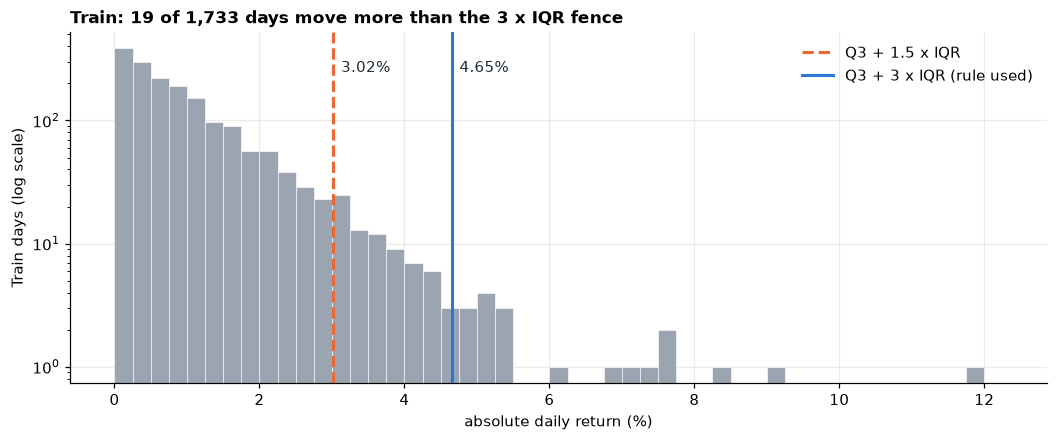

In [3]:
inner = fit_primary_spike_detector(train, multiplier=1.5)

fig, ax = plt.subplots(figsize=(9.5, 3.9), layout="constrained")
ax.hist(100 * absolute, bins=np.arange(0, 12.26, 0.25), color=GREY, edgecolor="white", linewidth=0.4)
ax.set_yscale("log")
marks = ((inner.threshold, "Q3 + 1.5 x IQR", ORANGE, "--"), (primary.threshold, "Q3 + 3 x IQR (rule used)", BLUE, "-"))
for value, label, color, style in marks:
    ax.axvline(100 * value, color=color, linestyle=style, linewidth=2)
    ax.annotate(f"{100 * value:.2f}%", (100 * value, 0.92), xycoords=("data", "axes fraction"),
                xytext=(5, 0), textcoords="offset points", color=INK, va="top")
ax.legend(handles=[Line2D([], [], color=color, linestyle=style, linewidth=2, label=label) for _, label, color, style in marks],
          frameon=False, loc="upper right")
ax.set_xlabel("absolute daily return (%)")
ax.set_ylabel("Train days (log scale)")
ax.set_title("Train: 19 of 1,733 days move more than the 3 x IQR fence", loc="left")
fig.savefig(FIGURE_DIR / "spike_threshold_distribution.png", bbox_inches="tight")
plt.show()

## 2. ทำไมใช้ควอร์ไทล์ ไม่ใช้ค่าเฉลี่ยกับ SD

วิธีหาค่าผิดปกติที่คุ้นกันที่สุดคือ "ห่างจากค่าเฉลี่ยเกิน 3 เท่าของส่วนเบี่ยงเบนมาตรฐาน (SD)" แต่วิธีนี้มีจุดอ่อนกับข้อมูลแบบของเรา คือ **SD ถูกดึงให้ใหญ่ขึ้นโดยวันสุดโต่งที่เรากำลังตามหา** เส้นแบ่งจึงขยับตามสิ่งที่มันควรจับ

ควอร์ไทล์ไม่มีปัญหานี้ เพราะ Q1 และ Q3 ดูแค่ลำดับของข้อมูล วันที่ร่วง 12% กับวันที่ร่วง 5% มีผลต่อ Q3 เท่ากัน คือเป็นเพียง "หนึ่งวันที่อยู่เหนือ Q3"

เซลล์ถัดไปทดสอบเรื่องนี้ตรง ๆ โดยคำนวณสถิติสองครั้ง ครั้งแรกใช้ Train ทั้งหมด ครั้งที่สองเอาวัน spike 19 วันออกก่อน แล้วดูว่าเส้นแบ่งแต่ละแบบขยับไปเท่าไร

In [4]:
def spread(frame):
    x = frame["return_1d"]
    q1, q3 = x.abs().quantile(0.25), x.abs().quantile(0.75)
    return {"SD of return (%)": 100 * x.std(ddof=1), "3 x SD cut (%)": 300 * x.std(ddof=1),
            "Q3 (%)": 100 * q3, "IQR (%)": 100 * (q3 - q1), "Q3 + 3 x IQR cut (%)": 100 * (q3 + 3 * (q3 - q1))}


robustness = pd.DataFrame({"all Train days": spread(train), "without the 19 spike days": spread(train[~direct])})
robustness["change (%)"] = 100 * (robustness.iloc[:, 1] / robustness.iloc[:, 0] - 1)
display(robustness.round(3))

,all Train days,without the 19 spike days,change (%)
SD of return (%),1.480,1.306,-11.762
3 x SD cut (%),4.439,3.917,-11.762
Q3 (%),1.387,1.350,-2.702
IQR (%),1.089,1.055,-3.121
Q3 + 3 x IQR cut (%),4.654,4.515,-2.996


**อ่านผล:** เมื่อเอาวัน spike เพียง 19 วัน (1.1% ของข้อมูล) ออก

- เส้นแบ่งแบบ **3 × SD ขยับ 11.8%** (จาก 4.44% เหลือ 3.92%)
- เส้นแบ่งแบบ **Q3 + 3 × IQR ขยับเพียง 3.0%** (จาก 4.65% เหลือ 4.51%)

เส้นแบ่งจากควอร์ไทล์จึงนิ่งกว่าราวสี่เท่า คุณสมบัตินี้เรียกว่า **robust** (ทนต่อค่าสุดโต่ง) และเป็นเหตุผลข้อแรกที่เลือกใช้ IQR

## 3. ทำไมใช้ตัวคูณ 3 ไม่ใช่ 1.5

กฎ IQR ที่พบในตำราสถิติมีสองระดับ ตามแนวของ Tukey (1977) ตัวคูณ **1.5** (inner fence) ใช้หา "ค่าผิดปกติทั่วไป" ส่วนตัวคูณ **3** (outer fence) ใช้หา "ค่าผิดปกติรุนแรง" เราต้องการอย่างหลัง เพราะคำถามวิจัยพูดถึงวันที่ราคา **กระชากแรงผิดปกติ** ไม่ใช่วันที่ผันผวนมากกว่าปกติเล็กน้อย

เซลล์ถัดไปแสดงว่าถ้าเลือกเกณฑ์อื่น ข้อมูลเทรนจะเหลือเท่าไร ทุกแถวใช้ขั้นตอนเดียวกับเกณฑ์หลัก คือหาเส้นแบ่งจาก Train แล้วตัดหน้าต่างรอบวัน spike ด้วย `src/spike_contract.py` (อธิบายในหัวข้อ 5)

ตารางนี้เป็น **การวิเคราะห์ผลต่อจำนวนข้อมูลเท่านั้น** ไม่มีการเทรนโมเดลด้วยเกณฑ์ทางเลือก และไม่ได้ใช้คะแนนของโมเดลมาเลือกเกณฑ์

In [5]:
def retention(name, threshold, flags):
    removed = build_affected_mask(flags)
    kept = ~removed
    return {"rule": name, "threshold (%)": 100 * threshold, "spike days": int(flags.sum()),
            "rows removed": int(removed.sum()), "rows removed (%)": 100 * removed.mean(),
            "rows left": int(kept.sum()), "high-vol days left": int(is_high[kept].sum()),
            "high-vol share left (%)": 100 * is_high[kept].mean()}


rules = []
for multiplier in (1.5, 2.0, 2.5, 3.0, 3.5, 4.0):
    fitted = fit_primary_spike_detector(train, multiplier=multiplier)
    rules.append(retention(f"Q3 + {multiplier:g} x IQR", fitted.threshold, apply_spike_detector(train, fitted)))
percentile_99 = float(absolute.quantile(0.99, interpolation="linear"))
rules.append(retention("99th percentile of |return|", percentile_99, absolute > percentile_99))
mean, sd = float(returns.mean()), float(returns.std(ddof=1))
rules.append(retention("|return - mean| > 3 x SD", 3 * sd, (returns - mean).abs() > 3 * sd))
median = float(absolute.median())
mad = float((absolute - median).abs().median())
rules.append(retention("robust z-score > 3.5", median + 3.5 * mad / 0.6745, 0.6745 * (absolute - median) / mad > 3.5))

sensitivity = pd.DataFrame(rules).set_index("rule")
USED = f"Q3 + {PRIMARY_SPIKE_IQR_MULTIPLIER:g} x IQR"
assert sensitivity.loc[USED, "rows removed"] == report["splits"]["train"]["affected_union_count"]
display(sensitivity.round(2))
print("Train before any rule:", len(train), "rows |", int(is_high.sum()), f"high-volatility days ({100 * is_high.mean():.1f}%)")

,threshold (%),spike days,rows removed,rows removed (%),rows left,high-vol days left,high-vol share left (%)
rule,,,,,,,
Q3 + 1.5 x IQR,3.02,91,690,39.82,1043,52,4.99
Q3 + 2 x IQR,3.57,52,557,32.14,1176,99,8.42
Q3 + 2.5 x IQR,4.11,32,368,21.23,1365,209,15.31
Q3 + 3 x IQR,4.65,19,213,12.29,1520,280,18.42
Q3 + 3.5 x IQR,5.20,12,120,6.92,1613,352,21.82
Q3 + 4 x IQR,5.74,9,95,5.48,1638,368,22.47
99th percentile of |return|,4.88,18,211,12.18,1522,281,18.46
|return - mean| > 3 x SD,4.44,24,282,16.27,1451,237,16.33
robust z-score > 3.5,3.21,72,638,36.81,1095,60,5.48


Train before any rule: 1733 rows | 433 high-volatility days (25.0%)


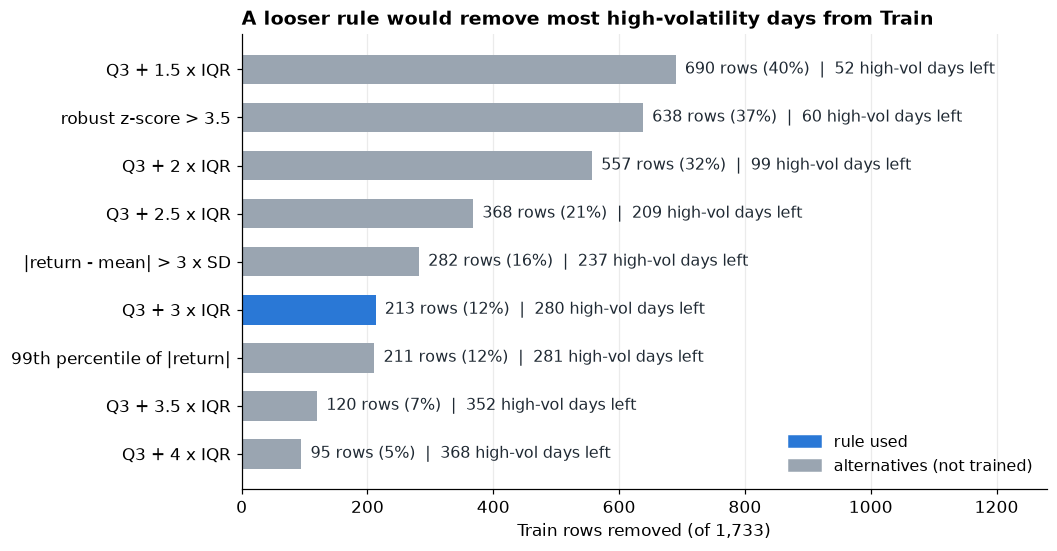

In [6]:
ordered = sensitivity.sort_values("rows removed")
colors = [BLUE if rule == USED else GREY for rule in ordered.index]

# Sized to stay readable when the same file is placed on a slide.
fig, ax = plt.subplots(figsize=(9.5, 4.9), layout="constrained")
bars = ax.barh(ordered.index, ordered["rows removed"], color=colors, height=0.62)
for bar, (_, row) in zip(bars, ordered.iterrows()):
    ax.annotate(f"{int(row['rows removed'])} rows ({row['rows removed (%)']:.0f}%)  |  {int(row['high-vol days left'])} high-vol days left",
                (bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10.5)
ax.set_xlim(0, 1280)
ax.set_xlabel(f"Train rows removed (of {len(train):,})", fontsize=11)
ax.tick_params(axis="both", labelsize=11)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLUE, label="rule used"), Patch(color=GREY, label="alternatives (not trained)")],
          frameon=False, loc="lower right", fontsize=10.5)
ax.set_title("A looser rule would remove most high-volatility days from Train", loc="left", fontsize=12.5)
fig.savefig(FIGURE_DIR / "spike_rule_sensitivity.png", bbox_inches="tight")
plt.show()

**อ่านผล:** Train เริ่มต้นมี 1,733 แถว และมีวันผันผวนสูง 433 วัน

- **ตัวคูณ 1.5** จับได้ 91 วัน และต้องตัด **690 แถว (40% ของ Train)** วันผันผวนสูงจะเหลือเพียง **52 จาก 433 วัน** ชุดข้อมูล "ไม่มี spike" จะกลายเป็นชุดข้อมูล "แทบไม่มีวันผันผวนสูง" การทดลองจะไม่ได้ตอบคำถามเรื่อง spike อีกต่อไป และ classifier แทบไม่มีตัวอย่างของคลาสที่ต้องทำนาย
- **ตัวคูณ 3 (ที่ใช้)** จับได้ 19 วัน ตัด **213 แถว (12%)** วันผันผวนสูงยังเหลือ 280 วัน มากพอให้โมเดลเรียนได้
- **เปอร์เซ็นไทล์ที่ 99** ให้ผลแทบเท่ากัน (18 วัน, 211 แถว) แปลว่าข้อสรุปไม่ได้ขึ้นกับการเลือกระหว่างสองนิยามของ "สุดโต่ง" นี้ เราเลือก IQR เพราะเส้นแบ่งมาจากรูปร่างของข้อมูลเอง ไม่ได้กำหนดล่วงหน้าว่าต้องมี 1% ของวันเป็น spike เสมอ
- **3 × SD** จับได้ 24 วัน ใกล้เคียงกัน แต่เส้นแบ่งไม่นิ่งตามที่เห็นในหัวข้อ 2
- **robust z-score** ที่เกณฑ์มาตรฐาน 3.5 เข้มน้อยกว่ามาก (72 วัน, ตัด 638 แถว) จึงมีปัญหาเดียวกับตัวคูณ 1.5

เหตุผลข้อที่สองจึงเป็น: **ตัวคูณ 3 ตัดเฉพาะวันที่สุดโต่งจริง และเหลือข้อมูลพอให้การเปรียบเทียบมีความหมาย**

ข้อควรระวัง: ตารางนี้ไม่ได้พิสูจน์ว่าตัวคูณ 3 "ดีที่สุด" มันแสดงเพียงว่าเกณฑ์ที่เข้มน้อยกว่าจะเปลี่ยนการทดลองเป็นอีกคำถามหนึ่ง

## 4. วันที่ถูกจัดเป็น spike คือวันไหน

ตารางถัดไปมาจาก `outputs/reports/spike_event_audit.csv` ซึ่งสายการเตรียมข้อมูลสร้างไว้ แต่ละวันถูกตรวจย้อนกลับไปถึงไฟล์ราคาดิบว่าตัวเลขตรงกันทุกขั้น เส้นแบ่งจาก Train ถูกนำไปใช้กับ Validation และ Test โดยไม่คำนวณใหม่ เพื่อติดป้ายวินิจฉัยเท่านั้น

,split,Date,return (%),episode,data_quality_status
0,train,2018-12-26,6.24,2018-12,market_movement
1,train,2020-02-27,-5.01,2020-02,market_movement
2,train,2020-03-02,5.16,2020-03,market_movement
3,train,2020-03-09,-6.95,2020-03,market_movement
4,train,2020-03-10,5.45,2020-03,market_movement
5,train,2020-03-12,-9.17,2020-03,market_movement
6,train,2020-03-13,8.47,2020-03,market_movement
7,train,2020-03-16,-11.98,2020-03,market_movement
8,train,2020-03-17,7.58,2020-03,market_movement
9,train,2020-03-24,7.74,2020-03,market_movement


events by split: {'test': 4, 'train': 19} | Validation: 0
data-quality status: {'market_movement': 23}


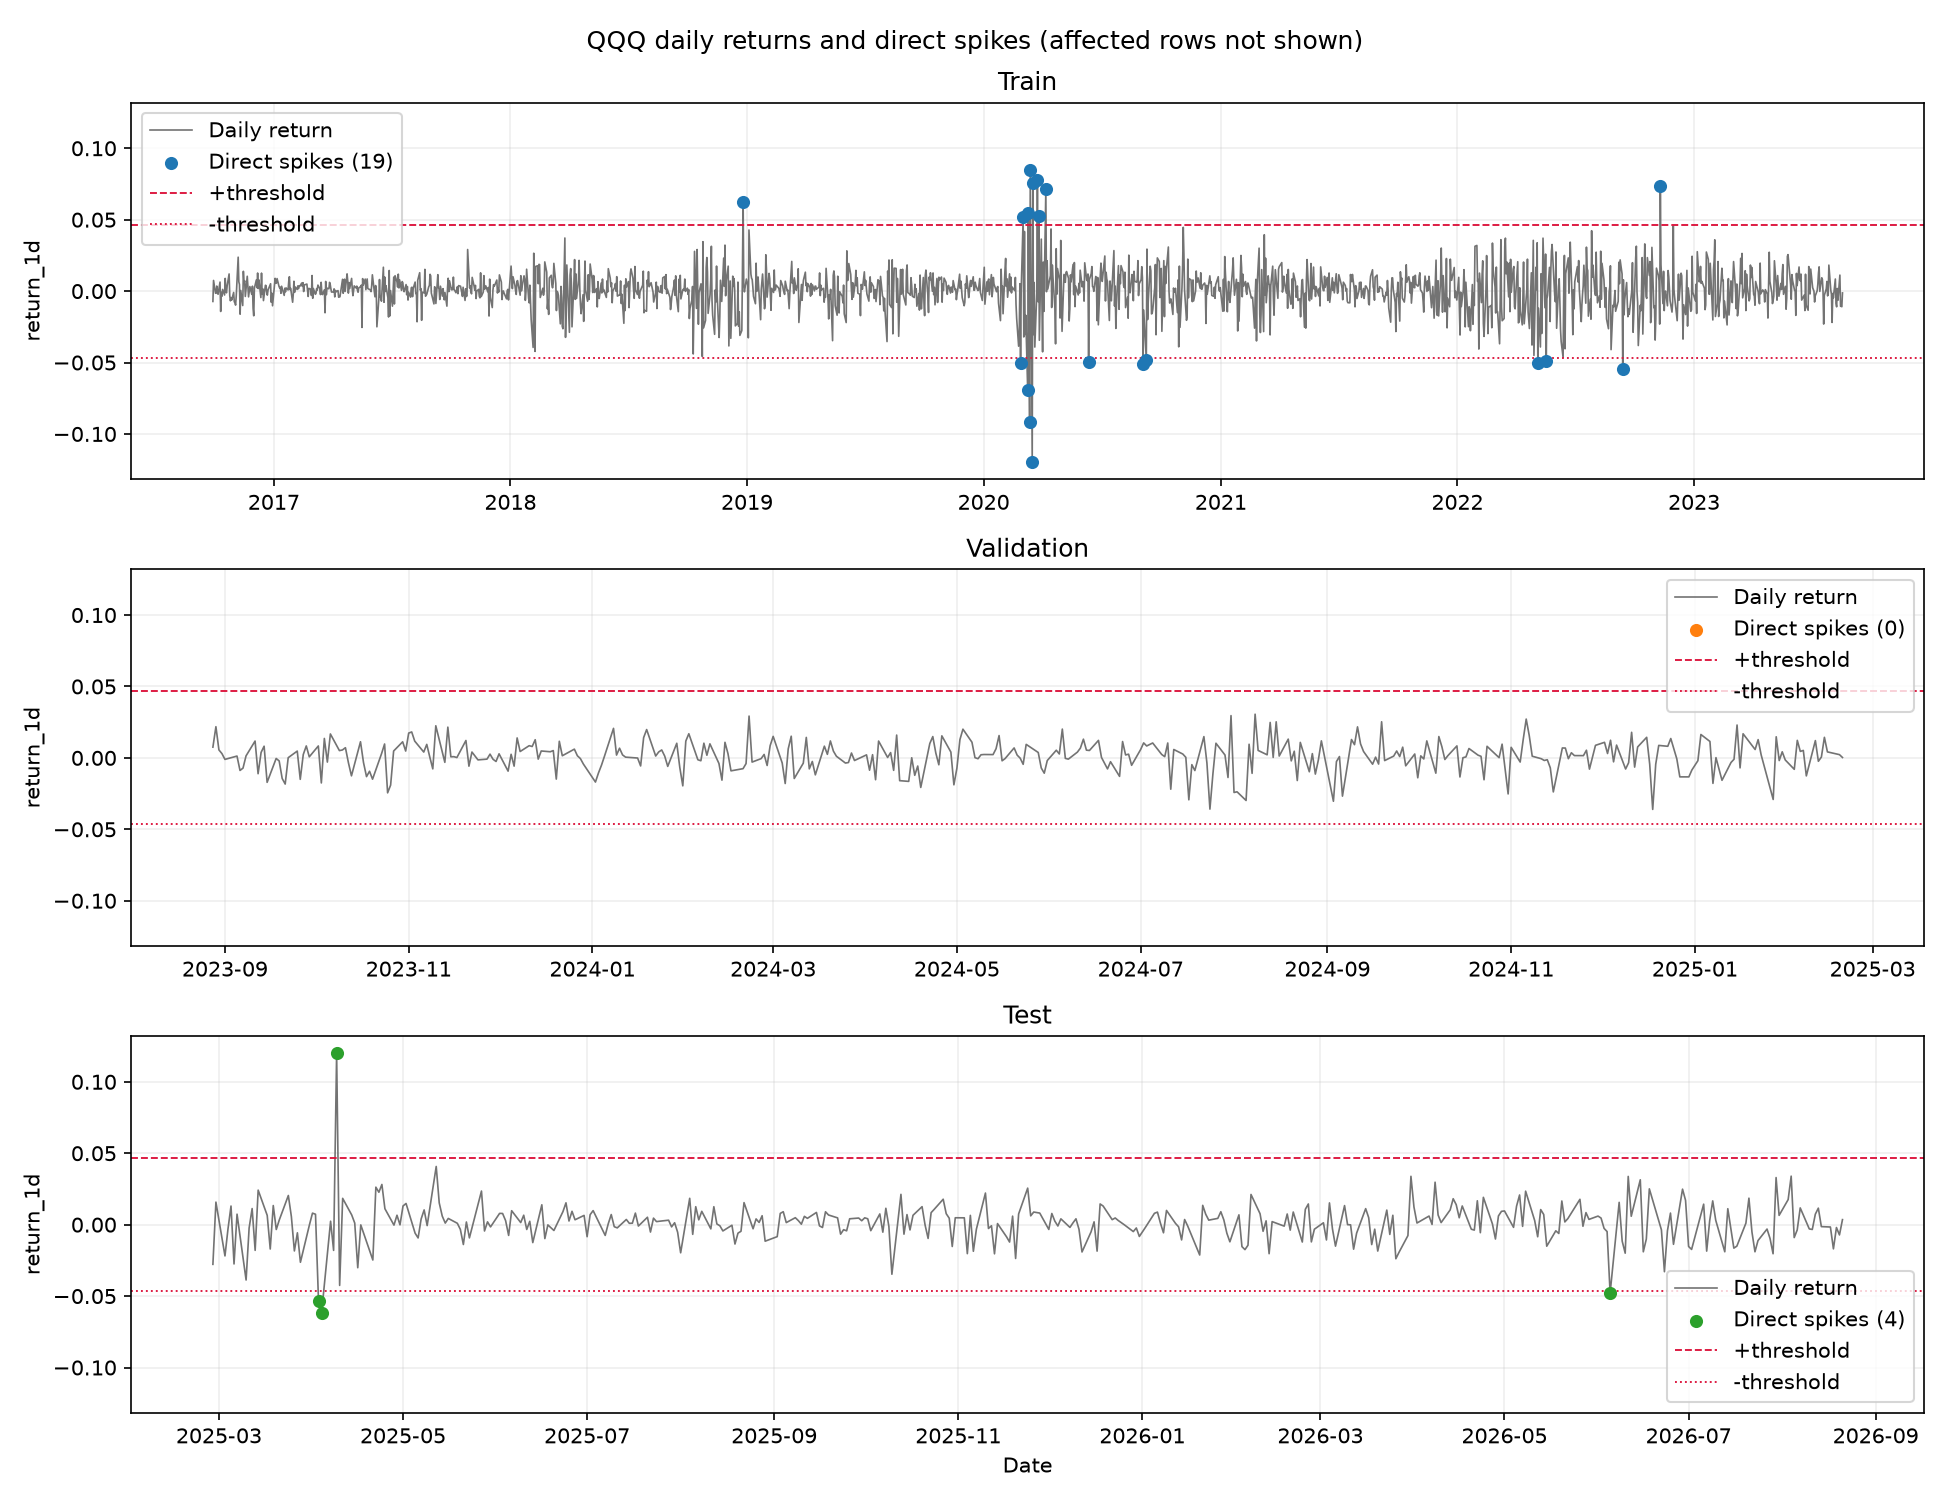

In [7]:
audit = pd.read_csv(SPIKE_EVENT_AUDIT_PATH, parse_dates=["Date"])
assert len(audit) == report["event_count"]
events = audit[["split", "Date", "return_1d", "data_quality_status"]].copy()
events["return (%)"] = (100 * events.pop("return_1d")).round(2)
events["episode"] = events["Date"].dt.strftime("%Y-%m")
events["Date"] = events["Date"].dt.date
display(events[["split", "Date", "return (%)", "episode", "data_quality_status"]])
print("events by split:", audit.groupby("split").size().to_dict(), "| Validation: 0")
print("data-quality status:", audit["data_quality_status"].value_counts().to_dict())
show_image(SPIKE_DAILY_RETURN_FIGURE_PATH, width=880)

**อ่านผล**

- Train มี 19 วัน กระจุกอยู่ใน 7 ช่วง คือ ธ.ค. 2018, ก.พ.–เม.ย. 2020 (11 วัน ซึ่งเป็นช่วงโควิด), มิ.ย. 2020, ก.ย. 2020, พ.ค. 2022, ก.ย. 2022 และ พ.ย. 2022 วันที่แรงที่สุดคือ 16 มี.ค. 2020 (−11.98%)
- Validation **ไม่มีวัน spike เลย** ส่วน Test มี 4 วัน (เม.ย. 2025 สามวัน และ มิ.ย. 2026 หนึ่งวัน)
- ทั้ง 23 วันถูกจัดเป็น `market_movement` คือเป็นการเคลื่อนไหวของตลาดจริง ไม่ใช่ข้อมูลผิดพลาด การตรวจนี้ใช้หลักฐานภายใน repo เท่านั้น ไม่ได้อ้างข่าวภายนอก

spike มาทั้งขาขึ้นและขาลง (เช่น +8.47% ในวันศุกร์ที่ 13 มี.ค. 2020 แล้ว −11.98% ในวันทำการถัดไป) จึงใช้ **ขนาด** ของผลตอบแทน ไม่ใช้เฉพาะวันที่ราคาลง

## 5. ทำไมต้องตัดทั้งช่วงรอบวัน spike

การตัดเฉพาะแถวของวัน spike ไม่พอ เพราะแถวข้างเคียงก็มีข้อมูลของวันนั้นอยู่ข้างใน

- **5 วันก่อน spike (s−5 ถึง s−1):** target ของวันเหล่านี้คือความผันผวนของ 5 วันถัดไป ซึ่งรวมวัน spike
- **วัน spike และ 19 วันถัดมา (s ถึง s+19):** feature ที่ดูย้อนหลัง 20 วัน เช่น `historical_volatility_20d` มีผลตอบแทนของวัน spike อยู่ในหน้าต่าง

จึงตัดช่วง **[s−5, s+19] รวม 25 แถวต่อ spike หนึ่งวัน** หน้าต่างของ spike ที่อยู่ใกล้กันซ้อนทับกันได้ และนับแต่ละแถวเพียงครั้งเดียว โค้ดอยู่ที่ `src/spike_contract.py`

เซลล์ถัดไปแสดงตัวอย่างจริงรอบวันที่ 26 ธ.ค. 2018 (+6.24%) ซึ่งเป็น spike ที่อยู่โดดเดี่ยว ไม่มี spike อื่นใน 294 วันทำการถัดมา

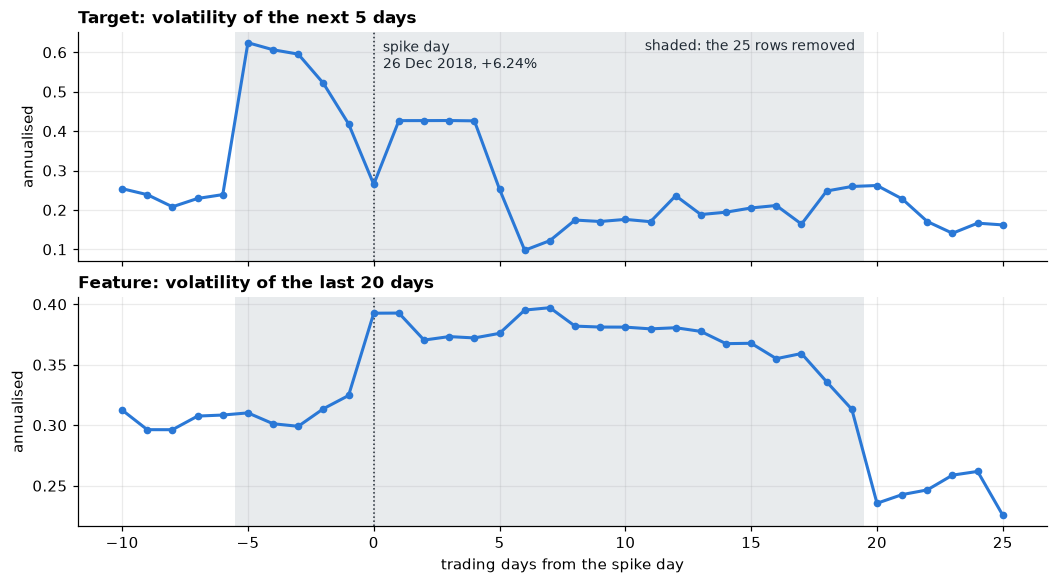

,Date,return_1d,target_volatility_5d,historical_volatility_20d
offset,,,,
-6,2018-12-17,-0.0227,0.2388,0.3084
-5,2018-12-18,0.0063,0.6242,0.3102
-1,2018-12-24,-0.0276,0.4183,0.3246
0,2018-12-26,0.0624,0.2648,0.3926
19,2019-01-24,0.0065,0.2595,0.3132
20,2019-01-25,0.0119,0.2620,0.2355


In [8]:
affected = build_affected_mask(direct)
assert int(affected.sum()) == report["splits"]["train"]["affected_union_count"]

spike_position = int(np.flatnonzero((train["Date"] == "2018-12-26").to_numpy())[0])
assert bool(direct.iloc[spike_position])
around = train.iloc[spike_position - 10:spike_position + 26].copy()
around["offset"] = np.arange(-10, 26)

fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.2), sharex=True, layout="constrained")
panels = (("target_volatility_5d", "Target: volatility of the next 5 days"),
          ("historical_volatility_20d", "Feature: volatility of the last 20 days"))
for ax, (column, title) in zip(axes, panels):
    ax.axvspan(-SPIKE_TARGET_BACKWARD_REACH - 0.5, SPIKE_FEATURE_FORWARD_REACH + 0.5, color=GREY, alpha=0.22, linewidth=0)
    ax.axvline(0, color=INK, linewidth=1, linestyle=":")
    ax.plot(around["offset"], around[column], color=BLUE, linewidth=2, marker="o", markersize=4)
    ax.set_title(title, loc="left")
    ax.set_ylabel("annualised")
axes[0].annotate("spike day\n26 Dec 2018, +6.24%", (0, 0.97), xycoords=("data", "axes fraction"),
                 xytext=(6, 0), textcoords="offset points", va="top", color=INK, fontsize=9)
axes[0].annotate("shaded: the 25 rows removed", (SPIKE_FEATURE_FORWARD_REACH + 0.5, 0.97), xycoords=("data", "axes fraction"),
                 xytext=(-6, 0), textcoords="offset points", va="top", ha="right", color=INK, fontsize=9)
axes[1].set_xlabel("trading days from the spike day")
fig.savefig(FIGURE_DIR / "affected_window_example.png", bbox_inches="tight")
plt.show()

display(around.loc[around["offset"].isin([-6, -5, -1, 0, 19, 20]),
                   ["offset", "Date", "return_1d", "target_volatility_5d", "historical_volatility_20d"]]
        .assign(Date=lambda frame: frame["Date"].dt.date).round(4).set_index("offset"))

**อ่านผล**

- **รูปบน (target):** ที่ระยะ −6 วัน target ยังเป็น 0.24 แต่ที่ −5 วันกระโดดเป็น 0.62 ทันที เพราะ "5 วันถัดไป" ของแถวนั้นเริ่มรวมวัน spike แล้ว ถ้าไม่ตัด 5 แถวนี้ โมเดลจะได้เรียนคำตอบที่ถูกวัน spike กำหนด
- **รูปล่าง (feature):** ความผันผวน 20 วันพุ่งขึ้นในวัน spike แล้วค้างสูงอยู่ครบ 20 วัน ก่อนลดลงทันทีที่ระยะ +20 (จาก 0.31 เหลือ 0.24) เพราะวัน spike หลุดออกจากหน้าต่างย้อนหลัง

ขอบของพื้นที่แรเงาจึงตรงกับจุดที่ข้อมูลของวัน spike เข้าและออกจากการคำนวณพอดี

ในรูปบน target สูงขึ้นอีกรอบที่ระยะ +1 ถึง +4 ช่วงนั้นไม่ได้มาจากวัน spike แต่มาจากวันที่ 3 และ 4 ม.ค. 2019 ที่ราคาขยับ −3.27% และ +4.28% ติดกัน ทั้งสองวันยังไม่ถึงเส้นแบ่ง 4.65% จึงไม่นับเป็น spike ตัวอย่างนี้แสดงด้วยว่าเกณฑ์จับเฉพาะวันที่สุดโต่งจริง วันที่ผันผวนสูงแบบทั่วไปยังอยู่ในข้อมูล

**ข้อจำกัดที่ยอมรับไว้:** `rsi_14` คำนวณแบบเฉลี่ยสะสม (Wilder) อิทธิพลของวัน spike จึงค่อย ๆ จางลงโดยไม่มีจุดตัดที่แน่นอน และอาจเหลืออยู่บ้างหลัง s+19 เราจึงเรียกชุดข้อมูลนี้ว่า "ตัดช่วงที่ได้รับผลจาก spike ตามนิยามที่ใช้" ไม่ได้อ้างว่าปราศจากอิทธิพลของ spike ในทุก feature

## 6. การตัดเปลี่ยนข้อมูลเทรนอย่างไร

ชุด `with_spike` คือ Train เดิมครบทุกแถว ส่วนชุด `non_spike` คือ Train เดิมที่ลบแถวในหน้าต่างออก **หลังจาก** สร้าง feature, target และป้ายเสร็จแล้ว ไม่มีการคำนวณค่าใดใหม่ แถวที่เหลือจึงมีค่าเหมือนต้นฉบับทุกคอลัมน์

,rows,high-vol days,high-vol share (%),largest target
with_spike (all Train),1733.0,433.0,24.99,1.50
non_spike (kept),1520.0,280.0,18.42,0.55
removed rows,213.0,153.0,71.83,1.50


,Train rows,rows removed,high-vol days,high-vol days removed
Date,,,,
2016,65,0,0,0
2017,251,0,0,0
2018,251,9,69,9
2019,252,16,26,2
2020,253,104,112,82
2021,252,0,45,0
2022,251,84,160,60
2023,158,0,21,0


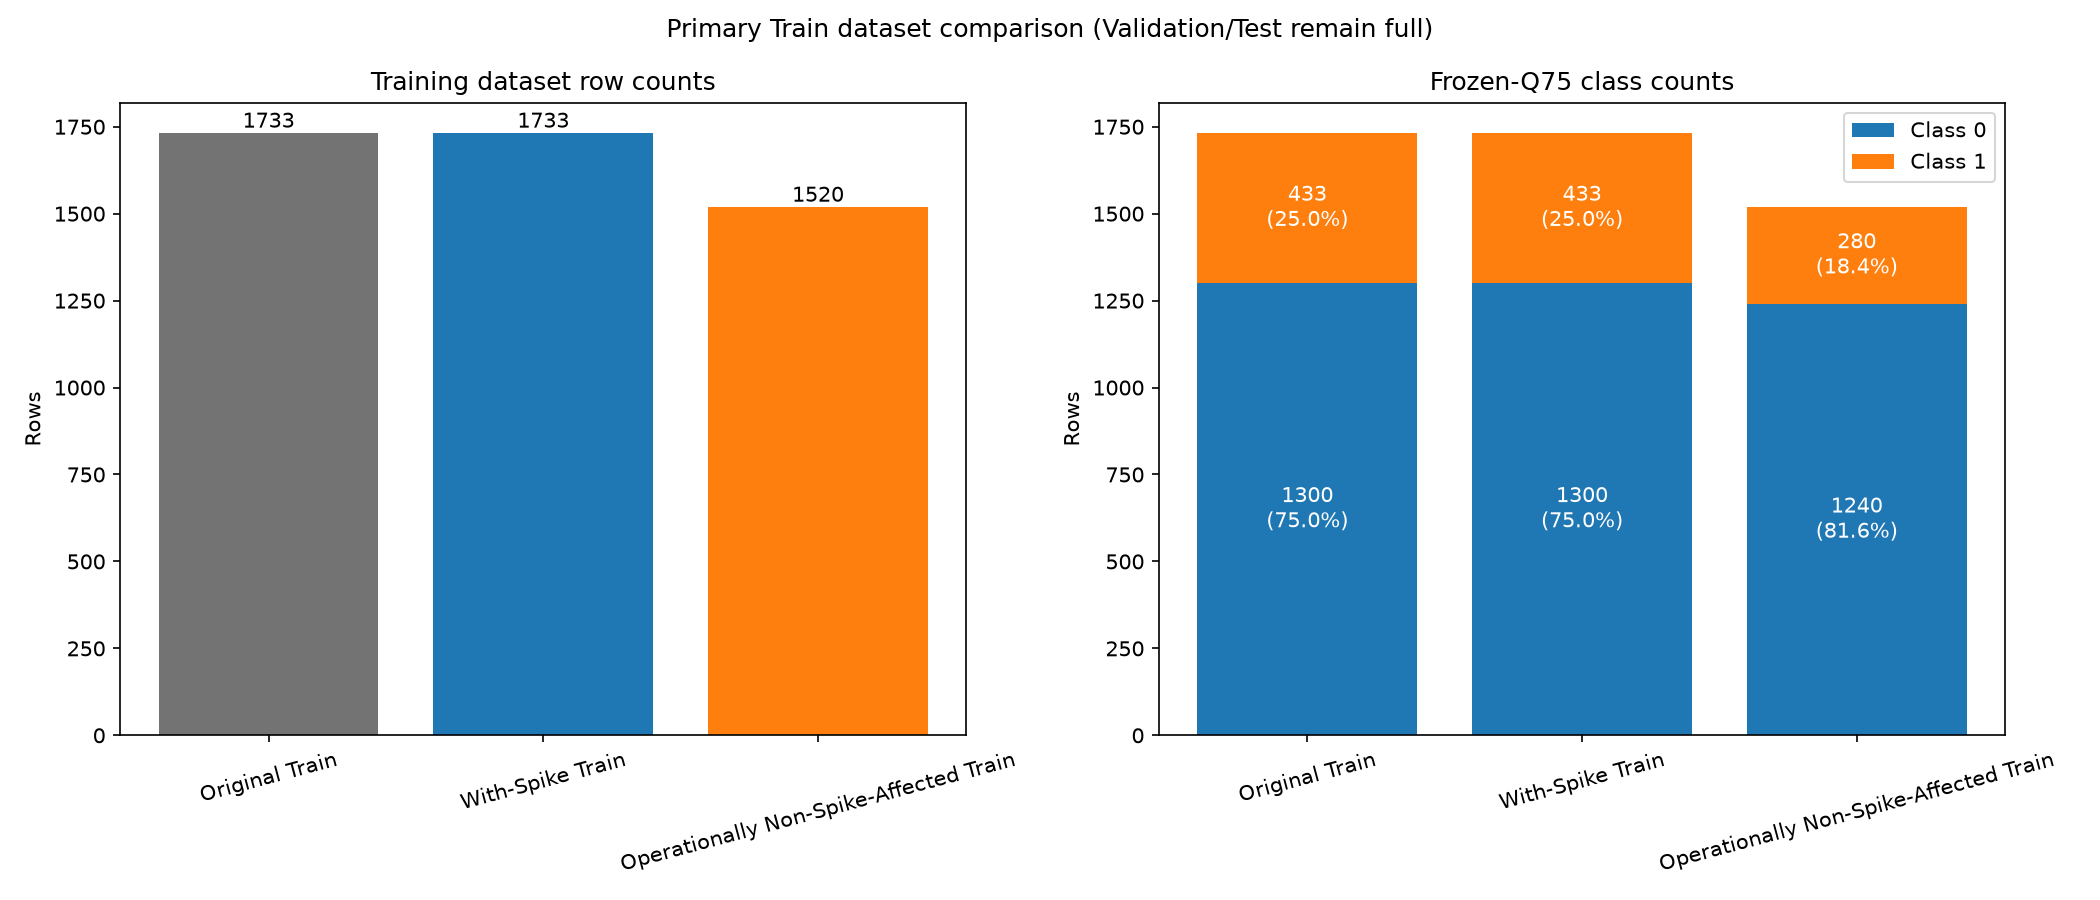

In [9]:
non_spike = pd.read_csv(NON_SPIKE_TRAIN_PATH, parse_dates=["Date"])
kept = train[~affected]
assert len(non_spike) == len(kept) and (non_spike["Date"].to_numpy() == kept["Date"].to_numpy()).all()

removed = train[affected]
summary = pd.DataFrame({
    "with_spike (all Train)": {"rows": len(train), "high-vol days": int(is_high.sum()),
                               "high-vol share (%)": 100 * is_high.mean(), "largest target": train["target_volatility_5d"].max()},
    "non_spike (kept)": {"rows": len(kept), "high-vol days": int(is_high[~affected].sum()),
                         "high-vol share (%)": 100 * is_high[~affected].mean(), "largest target": kept["target_volatility_5d"].max()},
    "removed rows": {"rows": len(removed), "high-vol days": int(is_high[affected].sum()),
                     "high-vol share (%)": 100 * is_high[affected].mean(), "largest target": removed["target_volatility_5d"].max()},
}).T
display(summary.round(2))

by_year = pd.DataFrame({"Train rows": train.groupby(train["Date"].dt.year).size(),
                        "rows removed": removed.groupby(removed["Date"].dt.year).size(),
                        "high-vol days": train.groupby(train["Date"].dt.year)["target_high_volatility"].sum().astype(int),
                        "high-vol days removed": removed.groupby(removed["Date"].dt.year)["target_high_volatility"].sum().astype(int)})
display(by_year.fillna(0).astype(int))
show_image(SPIKE_DATASET_COMPARISON_FIGURE_PATH, width=880)

**อ่านผล:** แถวที่ถูกตัด 213 แถว เป็นวันผันผวนสูงถึง 153 แถว (71.8%) และ 188 แถวอยู่ในปี 2020 กับ 2022 การตัดจึงเปลี่ยน **สามอย่างพร้อมกัน**

1. จำนวนแถวลดจาก 1,733 เหลือ 1,520
2. สัดส่วนวันผันผวนสูงลดจาก 25.0% เหลือ 18.4%
3. ช่วงตลาดปั่นป่วนที่สุดหายไปจากข้อมูลเทรน (ค่า target สูงสุดลดจาก 1.50 เหลือ 0.55)

สามอย่างนี้แยกจากกันไม่ได้ด้วยการทดลองนี้ ผลต่างระหว่างสองชุดข้อมูลจึงเป็นผลของ **นโยบายตัดแถวทั้งชุด** ไม่ใช่ผลของ spike เพียงอย่างเดียว

## 7. ทำไมไม่ตัด Validation และ Test

โมเดลที่เทรนจากทั้งสองชุดต้องถูกวัดบน **ข้อมูลชุดเดียวกันทุกแถว** จึงจะเทียบกันได้ตรง ๆ ถ้าตัด spike ออกจากข้อมูลวัดผลด้วย เราจะไม่รู้เลยว่าโมเดลที่ไม่เคยเห็น spike รับมือกับ spike ได้แย่ลงหรือไม่ ซึ่งเป็นครึ่งหนึ่งของคำถามวิจัย

เส้นแบ่งจาก Train ถูกนำไปติดป้ายแถวใน Validation และ Test เพื่อใช้ **แยกรายงานผลตามช่วงตลาด** เท่านั้น ตัวเลขด้านล่างมาจากรายงานของสายการเตรียมข้อมูล

In [10]:
segments = pd.DataFrame({name: {"rows": values["row_count"], "spike days": values["direct_count"],
                                "rows inside a window": values["affected_union_count"],
                                "rows outside every window": values["row_count"] - values["affected_union_count"]}
                         for name, values in report["splits"].items()}).T
display(segments)

,rows,spike days,rows inside a window,rows outside every window
train,1733,19,213,1520
validation,371,0,0,371
test,373,4,54,319


**อ่านผล:** Validation ไม่มีแถวใดอยู่ในหน้าต่างของ spike การเปรียบเทียบบน Validation จึงบอกได้เพียงว่าโมเดลทำงานอย่างไรในช่วงตลาดปกติ ส่วน Test มี 54 แถวอยู่ในหน้าต่าง และเป็นที่เดียวที่เห็นได้ว่าโมเดลแต่ละแบบรับมือกับช่วง spike อย่างไร

## 8. ผลต่อโมเดล

หัวข้อนี้อ่านจากไฟล์ผลที่มีอยู่แล้ว รายละเอียดทั้งหมดอยู่ใน `05_results_comparison.ipynb` ผลต่างคิดเป็น `non_spike − with_spike` บนข้อมูลชุดเดียวกัน พร้อมช่วงความเชื่อมั่น 95% แบบจับคู่ ถ้าช่วง **คร่อมศูนย์** แปลว่ายังบอกไม่ได้ว่าแบบไหนดีกว่า

In [11]:
comparison_path = REPORT_ROOT / "comparison_a_vs_b.csv"
require_files([comparison_path])
validation_pairs = pd.read_csv(comparison_path)
validation_pairs = validation_pairs[validation_pairs["task"] != "clustering"]
outcome = [{"split": "Validation (371 rows, no spike day)", "models compared": len(validation_pairs),
            "interval crosses zero": int((~validation_pairs["primary_excludes_zero"].astype(bool)).sum()),
            "non_spike clearly better": int((validation_pairs["verdict"] == "non_spike better").sum()),
            "with_spike clearly better": int((validation_pairs["verdict"] == "with_spike better").sum())}]

holdout_path = REPORT_ROOT / "tables" / "test_spike_policy.md"
if holdout_path.is_file():
    holdout_pairs = markdown_table(holdout_path)
    clear = holdout_pairs[holdout_pairs["interval_excludes_zero"] == "yes"]
    outcome.append({"split": "Test (373 rows, 54 inside a spike window)", "models compared": len(holdout_pairs),
                    "interval crosses zero": int((holdout_pairs["interval_excludes_zero"] == "no").sum()),
                    "non_spike clearly better": int((clear["direction"] == "non_spike better").sum()),
                    "with_spike clearly better": int((clear["direction"] == "with_spike better").sum())})
    display(clear[["task", "model", "metric", "with_spike", "non_spike", "delta", "delta_low", "delta_high", "direction"]])
display(pd.DataFrame(outcome).set_index("split"))

,task,model,metric,with_spike,non_spike,delta,delta_low,delta_high,direction
7,classification,perceptron,average_precision,0.1374,0.1328,-0.0046,-0.0313,-0.0001,with_spike better
9,classification,slp,average_precision,0.5536,0.4963,-0.0573,-0.1184,-0.0038,with_spike better
12,classification,xgboost,average_precision,0.5305,0.5823,0.0518,0.0163,0.0931,non_spike better


,models compared,interval crosses zero,non_spike clearly better,with_spike clearly better
split,,,,
"Validation (371 rows, no spike day)",17,16,1,0
"Test (373 rows, 54 inside a spike window)",17,14,1,2


**อ่านผล**

- บน **Validation** 16 จาก 17 โมเดลมีช่วงคร่อมศูนย์ และเมื่อเทียบ 17 โมเดลพร้อมกัน การพบ 1 โมเดลที่ช่วงไม่คร่อมศูนย์เกิดขึ้นได้โดยบังเอิญ
- บน **Test** 14 จาก 17 โมเดลมีช่วงคร่อมศูนย์ อีก 3 โมเดลชี้ไปคนละทาง คือ 2 โมเดลดีกว่าเมื่อเก็บ spike ไว้ และ 1 โมเดลดีกว่าเมื่อตัดออก
- ทิศทางของสองชุดข้อมูลไม่ตรงกัน

ข้อมูลชุดนี้จึง **ไม่สนับสนุน** ว่าการตัดช่วง spike ช่วยให้โมเดลดีขึ้น และไม่สนับสนุนว่าทำให้แย่ลง ผลต่างที่วัดได้เล็กกว่าความไม่แน่นอนของการวัด

## 9. ข้อจำกัด และสิ่งที่เล่มนี้ไม่ได้อ้าง

- **ไม่ได้อ้างว่า Q3 + 3 × IQR เป็นเกณฑ์ที่ดีที่สุด** เป็นเกณฑ์ที่กำหนดล่วงหน้าด้วยเหตุผลในหัวข้อ 2 และ 3 และถูกตรึงไว้ก่อนเห็นคะแนนของโมเดล
- **เกณฑ์ทางเลือกไม่ได้ถูกนำไปเทรน** ตารางในหัวข้อ 3 บอกได้เพียงว่าข้อมูลจะเหลือเท่าไร ไม่ได้บอกว่าโมเดลจะได้คะแนนเท่าไร
- **หน้าต่าง [s−5, s+19] เป็นนิยามเชิงปฏิบัติ** ครอบคลุม target และ feature ที่ใช้หน้าต่างคงที่ แต่ไม่ครอบคลุมอิทธิพลที่ค่อย ๆ จางของ `rsi_14`
- **หน้าต่างไม่ข้ามรอยต่อของชุดข้อมูล** mask คำนวณแยกในแต่ละชุด สำหรับเกณฑ์หลักไม่มี spike ใดอยู่ใกล้ขอบจนหน้าต่างถูกตัดสั้น
- **ผลของการตัดถูก confound** จำนวนแถว สัดส่วนคลาส และสภาพตลาดเปลี่ยนพร้อมกัน (หัวข้อ 6)
- **การตรวจว่าเป็นการเคลื่อนไหวของตลาดจริง** ใช้หลักฐานภายใน repo เท่านั้น

## 10. สรุป

| คำถาม | คำตอบ |
| --- | --- |
| ใช้เกณฑ์อะไร | วันที่ `\|return_1d\|` มากกว่า Q3 + 3 × IQR ของ Train ได้เส้นแบ่ง 4.65% พบ 19 วันใน Train |
| ทำไมใช้ IQR | เส้นแบ่งจากควอร์ไทล์ขยับเพียง 3.0% เมื่อเอาวัน spike ออก ส่วนเส้นแบ่งจาก SD ขยับ 11.8% |
| ทำไมใช้ตัวคูณ 3 | ตัวคูณ 1.5 จะตัด 40% ของ Train และเหลือวันผันผวนสูงเพียง 52 จาก 433 วัน ตัวคูณ 3 ตัด 12% และเหลือ 280 วัน |
| ทำไมตัดทั้งช่วง | target มองไปข้างหน้า 5 วัน และ feature มองย้อนหลัง 20 วัน จึงตัด [s−5, s+19] รวม 213 แถว |
| ผลต่อโมเดล | ยังสรุปไม่ได้ ช่วงความเชื่อมั่นคร่อมศูนย์ใน 16 จาก 17 โมเดลบน Validation และ 14 จาก 17 บน Test |

เกณฑ์นี้ถูกเลือกจากหลักการก่อนเห็นผลของโมเดล คำนวณจาก Train เท่านั้น และไม่ถูกปรับหลังจากนั้น

In [12]:
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("Train file sha256 recorded in the spike report:", report["inputs"]["train_labeled"]["sha256"][:16].lower())
print("figures written to", FIGURE_DIR.relative_to(project_root).as_posix() + ":", sorted(path.name for path in FIGURE_DIR.glob("*.png")))

Python 3.14.8 | NumPy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2
Train file sha256 recorded in the spike report: 424f1bda5c4211ac
figures written to outputs/figures/modeling/spike_rule: ['affected_window_example.png', 'spike_rule_sensitivity.png', 'spike_threshold_distribution.png']
